# Models

Input: `data/model_table.csv`, built by `python analysis/build_model_table.py` (column glossary at the top of that script). One row per game, home-team perspective.

| Section | Question |
|---|---|
| 1 | Do the de-vig methods disagree? |
| 2 | Are Kalshi / sportsbook prices calibrated against outcomes? |
| 3 | Does the sportsbook price carry information Kalshi missed (and vice versa)? |
| 4 | Do past Kalshi prices predict beyond the close? (needs `scripts/fetch_kalshi_early_prices.py`) |
| 5 | Does the size of the disagreement shrink with liquidity? |
| 6 | Robustness: de-vig method, low-volume games, regular season only |
| 7 | Is anything exploitable after the spread and fees? |
| 8 | Price leadership: when the venues disagree, which one has the information? (exploratory) |
| 9 | Where are the markets least efficient? Pre-specified subgroups, multiple-testing corrected (exploratory) |

Strong form is not testable with public price data!

**Conventions.**
- Standard errors are clustered by `game_date_et`, since same-day games share news and bettors.
- `gap = sportsbook − Kalshi`, matching the EDA.
- The primary de-vig method is **Cheung** (odds-ratio), fixed before looking at results.

A summary of answers to the research questions is at the end of the notebook.

In [28]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

df = pd.read_csv("../data/model_table.csv", parse_dates=["start_time_utc"])
df = df.sort_values("start_time_utc").reset_index(drop=True)
df["post"] = df["postseason"].astype(int)
df["ba_spread_c"] = 100 * df["kalshi_ba_spread"]   # bid-ask spread in cents

SPORT_ORDER = ["nfl", "mlb", "nba", "nhl"]
SPORT_COLORS = {"nfl": "#2a78d6", "mlb": "#eb6834", "nba": "#1baf7a", "nhl": "#eda100"}
DEVIG_METHODS = ["proportional", "additive", "shin", "power", "cheung"]
PRIMARY_DEVIG = "cheung"
CONTROLS = "C(sport) + post + season_progress + months_since_start + n_sports_today + lopsided"

print(df.shape)
df.groupby("sport").size().reindex(SPORT_ORDER)

(4865, 63)


sport
nfl     276
mlb    1991
nba    1214
nhl    1384
dtype: int64

In [29]:
# ---------- helpers ----------
def cluster(data):
    # Arguments for .fit() that cluster standard errors by game date.
    return dict(cov_type="cluster", cov_kwds={"groups": pd.factorize(data["game_date_et"])[0]})


def logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def with_book_method(data, method):
    # Copy of data with every sportsbook-derived column recomputed for one de-vig method.
    d = data.copy()
    d["p_book"] = d[f"p_book_{method}"]
    d["logit_book"] = logit(d["p_book"])
    d["logit_gap"] = d["logit_book"] - d["logit_kalshi"]
    d["abs_logit_gap"] = d["logit_gap"].abs()
    d["gap_pp"] = 100 * (d["p_book"] - d["p_kalshi"])
    d["lopsided"] = (d["p_kalshi"] + d["p_book"] - 1).abs()
    return d


def calibration_fit(data, xcol):
    # logit P(home_win) = a + b * xcol, clustered SEs, joint Wald test of (a = 0, b = 1).
    res = smf.logit(f"home_win ~ {xcol}", data=data).fit(disp=0, **cluster(data))
    w = res.wald_test(f"Intercept = 0, {xcol} = 1", scalar=True)
    lo, hi = res.conf_int().loc[xcol]
    return res, {"n": int(res.nobs), "alpha": res.params["Intercept"], "alpha_se": res.bse["Intercept"],
                 "beta": res.params[xcol], "beta_lo": lo, "beta_hi": hi,
                 "wald_chi2": float(w.statistic), "wald_p": float(w.pvalue)}


def calibration_plot(data, p_col, label, bins=10, ax=None, **kw):
    # Reliability diagram: mean predicted vs observed win rate in probability deciles.
    ax = ax or plt.gca()
    b = pd.qcut(data[p_col], bins, duplicates="drop")
    g = data.groupby(b, observed=True).agg(pred=(p_col, "mean"), obs=("home_win", "mean"), n=("home_win", "size"))
    se = np.sqrt(g["obs"] * (1 - g["obs"]) / g["n"])
    ax.errorbar(g["pred"], g["obs"], yerr=1.96 * se, fmt="o", ms=4, capsize=2, label=label, **kw)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("predicted P(home win)"); ax.set_ylabel("observed home win rate")
    return g


def by_sport(data, fn):
    # Run fn(sub_df) -> dict for the pooled sample and each sport; return a DataFrame.
    rows = [{"sample": "pooled", **fn(data)}]
    for s in SPORT_ORDER:
        rows.append({"sample": s, **fn(data[data["sport"] == s])})
    return pd.DataFrame(rows).set_index("sample")

## 1. De-vig sensitivity (descriptive)

The method is fixed up front as Cheung, and the others are reported for sensitivity. For a two-outcome market, Shin's method gives exactly the additive answer, so the `shin` and `additive` rows match.

In [30]:
rows = []
for m in DEVIG_METHODS:
    g = 100 * (df[f"p_book_{m}"] - df["p_kalshi"])
    rows.append({"method": m, "mean_gap_pp": g.mean(), "sd_gap_pp": g.std(),
                 "median_abs_gap_pp": g.abs().median(), "share_book_above_kalshi": (g > 0).mean()})
devig_table = pd.DataFrame(rows).set_index("method")
devig_table.round(3)

,mean_gap_pp,sd_gap_pp,median_abs_gap_pp,share_book_above_kalshi
method,,,,
proportional,-0.025,0.995,0.626,0.488
additive,0.138,0.912,0.596,0.565
shin,0.138,0.912,0.596,0.568
power,0.227,1.029,0.697,0.592
cheung,0.149,0.921,0.601,0.574


In [31]:
# Mean gap by sport under each method
pd.DataFrame({m: (100 * (df[f"p_book_{m}"] - df["p_kalshi"])).groupby(df["sport"]).mean()
              for m in DEVIG_METHODS}).reindex(SPORT_ORDER).round(3)

,proportional,additive,shin,power,cheung
sport,,,,,
nfl,-0.152,0.040,0.040,0.152,0.057
mlb,-0.017,0.126,0.126,0.200,0.133
nba,-0.066,0.143,0.143,0.267,0.163
nhl,0.025,0.171,0.171,0.246,0.178


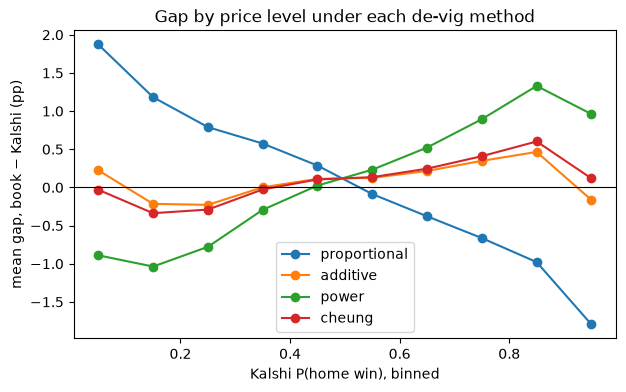

In [32]:
# Where do the methods disagree? Mean gap within bins of the Kalshi price.
bins = pd.cut(df["p_kalshi"], np.arange(0, 1.0001, 0.1))
fig, ax = plt.subplots(figsize=(7, 4))
for m in ["proportional", "additive", "power", "cheung"]:
    g = (100 * (df[f"p_book_{m}"] - df["p_kalshi"])).groupby(bins, observed=True).mean()
    ax.plot([iv.mid for iv in g.index], g.values, marker="o", label=m)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Kalshi P(home win), binned"); ax.set_ylabel("mean gap, book − Kalshi (pp)")
ax.set_title("Gap by price level under each de-vig method"); ax.legend();

**Reading section 1.**
- The de-vig choice changes the *sign* of the average gap: proportional gives −0.03 pp (book slightly below Kalshi), while Cheung, additive and power give +0.14 to +0.23 pp. This holds in every sport.
- The plot shows why. Proportional de-vigging gives favorites too much of the vig (book > Kalshi for longshots, book < Kalshi for favorites, by up to about 2 pp). Power tilts the other way. Cheung and additive sit flattest against Kalshi, i.e. closest to how Kalshi traders themselves price the favorite/longshot split.
- So any statement about the *direction* of the Kalshi–book gap is method-dependent and should be reported with this table. Statements about calibration against outcomes (section 2) are not, at least on the Kalshi side.

## 2. Calibration

For each source $s$: $\;\text{logit}\,P(\text{home\_win}=1) = \alpha + \beta\,\text{logit}(p_s)$.

- **Perfect calibration:** $\alpha = 0$ and $\beta = 1$, tested jointly with a Wald test.
- $\beta > 1$: prices are too compressed toward 50%, i.e. favorites underpriced (favorite-longshot bias).
- $\beta < 1$: prices are too extreme.
- $\alpha \ne 0$: a systematic home/away bias in prices.

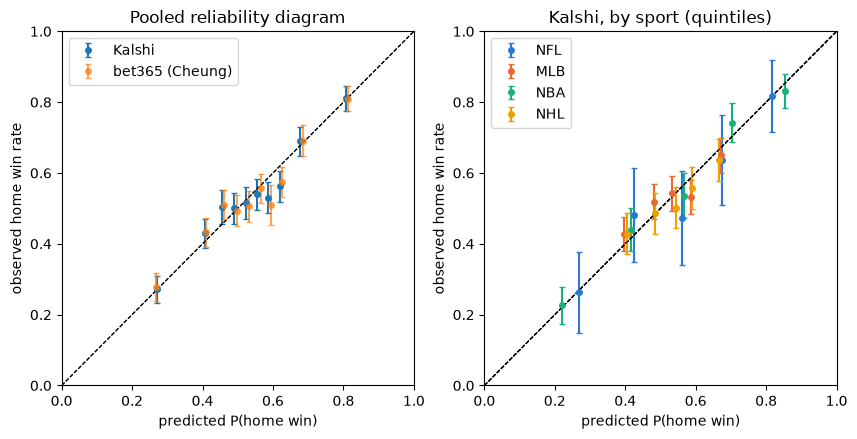

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
calibration_plot(df, "p_kalshi", "Kalshi", ax=axes[0])
calibration_plot(df, "p_book", "bet365 (Cheung)", ax=axes[0], alpha=0.7)
axes[0].set_title("Pooled reliability diagram"); axes[0].legend()
for s in SPORT_ORDER:
    calibration_plot(df[df.sport == s], "p_kalshi", s.upper(), bins=5, ax=axes[1], color=SPORT_COLORS[s])
axes[1].set_title("Kalshi, by sport (quintiles)"); axes[1].legend();

### 2a–b. Calibration regressions, pooled and by sport

In [34]:
calib_kalshi = by_sport(df, lambda d: calibration_fit(d, "logit_kalshi")[1])
calib_book = by_sport(df, lambda d: calibration_fit(d, "logit_book")[1])
print("Kalshi")
display(calib_kalshi.round(3))
print("bet365 (Cheung)")
calib_book.round(3)

Kalshi


,n,alpha,alpha_se,beta,beta_lo,beta_hi,wald_chi2,wald_p
sample,,,,,,,,
pooled,4865,-0.011,0.029,0.943,0.844,1.041,1.613,0.446
nfl,276,-0.065,0.140,0.967,0.682,1.253,0.258,0.879
mlb,1991,0.027,0.046,0.789,0.565,1.012,3.436,0.179
nba,1214,0.015,0.061,1.018,0.876,1.159,0.138,0.933
nhl,1384,-0.041,0.056,0.834,0.548,1.120,2.590,0.274


bet365 (Cheung)


,n,alpha,alpha_se,beta,beta_lo,beta_hi,wald_chi2,wald_p
sample,,,,,,,,
pooled,4865,-0.014,0.029,0.921,0.825,1.017,3.152,0.207
nfl,276,-0.059,0.140,0.915,0.647,1.183,0.555,0.758
mlb,1991,0.024,0.046,0.773,0.552,0.994,4.044,0.132
nba,1214,0.010,0.061,0.998,0.859,1.137,0.027,0.987
nhl,1384,-0.045,0.056,0.817,0.537,1.097,3.253,0.197


In [35]:
# Do the slopes differ by sport? Interaction model, Wald test that all sport:slope interactions are 0.
for x in ["logit_kalshi", "logit_book"]:
    res = smf.logit(f"home_win ~ C(sport) * {x}", data=df).fit(disp=0, **cluster(df))
    terms = [t for t in res.params.index if ":" in t]
    w = res.wald_test(", ".join(f"{t} = 0" for t in terms), scalar=True)
    print(f"{x}: equal slopes across sports  chi2({len(terms)}) = {w.statistic:.2f}, p = {w.pvalue:.3f}")

logit_kalshi: equal slopes across sports  chi2(3) = 3.50, p = 0.321
logit_book: equal slopes across sports  chi2(3) = 3.41, p = 0.332


### 2c. Does calibration change with season phase or platform maturity?

In [36]:
rows = []
for term in ["post", "season_progress", "months_since_start", "log_volume"]:
    res = smf.logit(f"home_win ~ logit_kalshi * {term}", data=df).fit(disp=0, **cluster(df))
    k = f"logit_kalshi:{term}"
    lo, hi = res.conf_int().loc[k]
    rows.append({"moderator": term, "slope_interaction": res.params[k], "lo": lo, "hi": hi, "p": res.pvalues[k]})
pd.DataFrame(rows).set_index("moderator").round(4)

,slope_interaction,lo,hi,p
moderator,,,,
post,-0.0894,-0.6154,0.4365,0.7390
season_progress,0.2195,-0.0913,0.5303,0.1663
months_since_start,0.0321,0.0004,0.0638,0.0473
log_volume,0.0067,-0.0323,0.0456,0.7374


### 2d. Which source forecasts better? Brier score and log loss

A model-free comparison. The paired difference (Kalshi loss − book loss) is tested by regressing it on a constant with date-clustered SEs, which is a Diebold–Mariano-style test.

In [37]:
def scores(d):
    y = d["home_win"]
    out = {}
    for name, p in [("kalshi", d["p_kalshi"]), ("book", d["p_book"])]:
        out[f"brier_{name}"] = ((p - y) ** 2).mean()
        out[f"logloss_{name}"] = -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()
    diff = (d["p_kalshi"] - y) ** 2 - (d["p_book"] - y) ** 2
    r = smf.ols("diff ~ 1", data=d.assign(diff=diff)).fit(**cluster(d))
    out["brier_diff_x1000"] = 1000 * r.params.iloc[0]
    out["diff_p"] = r.pvalues.iloc[0]
    out["brier_coinflip"] = 0.25
    return out

forecast_scores = by_sport(df, scores)
forecast_scores.round(4)

,brier_kalshi,logloss_kalshi,brier_book,logloss_book,brier_diff_x1000,diff_p,brier_coinflip
sample,,,,,,,
pooled,0.2301,0.6495,0.2303,0.6500,-0.2389,0.0488,0.25
nfl,0.2133,0.6119,0.2145,0.6143,-1.1700,0.0131,0.25
mlb,0.2436,0.6798,0.2438,0.6802,-0.2035,0.3233,0.25
nba,0.1957,0.5723,0.1959,0.5728,-0.1689,0.4566,0.25
nhl,0.2441,0.6810,0.2443,0.6813,-0.1654,0.4102,0.25


**Reading section 2.**
- **Both markets are well calibrated.** Pooled Kalshi: α = −0.01, β = 0.94 (95% CI 0.84–1.04); the joint test of α = 0, β = 1 gives p = 0.45. bet365 is nearly identical (β = 0.92, CI 0.83–1.02, p = 0.21). No sport rejects calibration, and the slopes don't differ significantly across sports (p ≈ 0.32).
- The point estimates of β are all slightly **below 1**, most visibly for MLB (0.79, CI 0.57–1.01). That points at mild over-extremity: favorites a little overpriced, underdogs a little underpriced. It's the opposite of the classic favorite-longshot bias, and it isn't significant. Section 7a shows the same thing in money terms: underdogs bought at the ask return +3.6% before fees.
- Calibration doesn't change with postseason, season progress or volume. The slope does rise with platform age (+0.03 per month, p = 0.047). But that's one of four moderators tested, and platform age is confounded with sport (early Kalshi = MLB only), so treat it as suggestive rather than as evidence the market "learned".
- On Brier score, Kalshi is very slightly better than bet365 (difference 0.00024 pooled, p = 0.049). The NFL shows the clearest difference (p = 0.013, but n = 276). Both are far better than a coin flip (0.25).
- **Write-up phrasing:** "we cannot reject calibration; the data rule out slopes outside about 0.84–1.04", rather than just "not significant".

## 3. Semi-strong form: encompassing test

The sportsbook price is public at kickoff. If Kalshi is semi-strong efficient, the book adds nothing beyond the Kalshi price:

$$\text{logit}\,P = \alpha + \beta_1\,\text{logit}(p_K) + \beta_2\,\text{logit}(p_B), \qquad H_0: \beta_2 = 0.$$

`logit_kalshi` and `logit_book` correlate at about 0.999, so the model is fit in the equivalent, well-conditioned form

$$\text{logit}\,P = \alpha + (\beta_1+\beta_2)\,\text{logit}(p_K) + \beta_2\,\texttt{logit\_gap}.$$

The coefficient on `logit_gap` is $\beta_2$. Positive means that when the book is more bullish than Kalshi, the book tends to be right.

The reverse question (does Kalshi add anything beyond the book?) uses `logit_book` as the base. There the gap coefficient equals $-\beta_1$, so a *negative* value means Kalshi carries extra information.

In [38]:
def encompassing(d):
    rk = smf.logit("home_win ~ logit_kalshi + logit_gap", data=d).fit(disp=0, **cluster(d))
    rb = smf.logit("home_win ~ logit_book + logit_gap", data=d).fit(disp=0, **cluster(d))
    lo_k, hi_k = rk.conf_int().loc["logit_gap"]
    lo_b, hi_b = rb.conf_int().loc["logit_gap"]
    return {"n": int(rk.nobs),
            "book_adds_to_kalshi": rk.params["logit_gap"], "bk_lo": lo_k, "bk_hi": hi_k, "bk_p": rk.pvalues["logit_gap"],
            "kalshi_adds_to_book(-b1)": rb.params["logit_gap"], "kb_lo": lo_b, "kb_hi": hi_b, "kb_p": rb.pvalues["logit_gap"]}

encompass = by_sport(df, encompassing)
encompass.round(3)

,n,book_adds_to_kalshi,bk_lo,bk_hi,bk_p,kalshi_adds_to_book(-b1),kb_lo,kb_hi,kb_p
sample,,,,,,,,,
pooled,4865,-0.593,-1.939,0.754,0.388,-1.545,-2.922,-0.168,0.028
nfl,276,-3.589,-8.566,1.387,0.157,-4.717,-10.035,0.602,0.082
mlb,1991,-0.443,-2.392,1.506,0.656,-1.233,-3.201,0.736,0.220
nba,1214,-0.791,-3.402,1.819,0.552,-1.823,-4.485,0.839,0.180
nhl,1384,-0.092,-3.560,3.376,0.959,-0.927,-4.469,2.614,0.608


In [39]:
# How big is a gap coefficient in probability terms? Effect of a 1-SD logit_gap at p = 0.5.
sd_gap = df["logit_gap"].std()
b2 = encompass.loc["pooled", "book_adds_to_kalshi"]
lo, hi = encompass.loc["pooled", ["bk_lo", "bk_hi"]]
pp = lambda b: 100 * (1 / (1 + np.exp(-b * sd_gap)) - 0.5)
print(f"SD of logit_gap = {sd_gap:.4f}")
print(f"1-SD gap moves P(win) at p=0.5 by {pp(b2):+.2f} pp  (95% CI {pp(lo):+.2f} to {pp(hi):+.2f} pp)")

SD of logit_gap = 0.0465
1-SD gap moves P(win) at p=0.5 by -0.69 pp  (95% CI -2.25 to +0.88 pp)


**Reading section 3.**
- **Book → Kalshi: no evidence of semi-strong inefficiency.** Once you know the Kalshi price, the bet365 price adds nothing (coefficient −0.59, CI −1.94 to 0.75, p = 0.39). The coefficient is not even positive, and no sport shows it. In probability terms, a one-SD gap moves the win probability by −0.7 pp (CI −2.3 to +0.9 pp), so any book-side information Kalshi misses is at most about 1 pp.
- **Kalshi → book: Kalshi does carry information the book lacks** (pooled −β₁ = −1.55, CI −2.92 to −0.17, p = 0.028). In words: when Kalshi is more bullish on a team than bet365, Kalshi tends to be right. So the Kalshi closing price *encompasses* the bet365 price, but not vice versa.
- A likely reason is **timing**. The Kalshi price is the last candle before kickoff, while the scraped bet365 line may be from earlier, so Kalshi has seen more news (lineups, injuries, late money). This is worth stating as a caveat: it's evidence about *these two snapshots*, not proof that Kalshi traders are smarter.
- Within sports the intervals are wide and nothing is individually significant. The pooled result comes from combining them.

## 4. Weak form: does line movement predict beyond the close?

The weak form asks whether **past Kalshi prices** predict outcomes once you know the closing price. For each horizon $h$ = 24, 6 and 2 hours before kickoff:

$$\text{logit}\,P(\text{home\_win}) = \alpha + \beta\,\text{logit}(p_{\text{close}}) + \gamma\,\underbrace{\big[\text{logit}(p_{\text{close}}) - \text{logit}(p_{T-h})\big]}_{\texttt{move\_}h\texttt{h}}$$

- **Weak-form efficiency:** $\gamma = 0$. The path the price took adds nothing to where it ended.
- $\gamma > 0$: **momentum / under-reaction.** Moves into the close tend to continue, so the close hasn't fully absorbed the news.
- $\gamma < 0$: **over-reaction.** Moves into the close tend to partly reverse.

Early prices are the normalized Kalshi mid (home mid ÷ sum of mids) from the last 1-minute candle at or before $T-h$, kept only when both sides had a two-sided quote. They come from `scripts/fetch_kalshi_early_prices.py`, merged by `analysis/build_model_table.py`. Each horizon uses the games with a quote at that horizon, so sample sizes differ. Standard errors are clustered by date, as elsewhere.

The last table drops games whose $T-h$ quote is more than 2 hours stale (a thin market carrying an old quote forward), as a robustness check.

In [40]:
HORIZONS = [h for h in (24, 6, 2) if f"move_{h}h" in df]
if not HORIZONS:
    print("No early Kalshi prices in model_table.csv. Run `python scripts/fetch_kalshi_early_prices.py`, "
          "then `python analysis/build_model_table.py`, and rerun this notebook.")


def weak_form(d, h):
    # home_win ~ logit_kalshi + move_h on games with a T-h quote; gamma = coefficient on move_h.
    m = f"move_{h}h"
    d = d.dropna(subset=[m])
    if len(d) < 50:
        return {"n": len(d)}
    r = smf.logit(f"home_win ~ logit_kalshi + {m}", data=d).fit(disp=0, **cluster(d))
    lo, hi = r.conf_int().loc[m]
    y = d["home_win"]
    return {"n": int(r.nobs), "beta_close": r.params["logit_kalshi"],
            "gamma_move": r.params[m], "g_lo": lo, "g_hi": hi, "g_p": r.pvalues[m],
            "sd_move": d[m].std(), "share_moved": (d[m].abs() > 1e-9).mean(),
            "brier_close": ((d["p_kalshi"] - y) ** 2).mean(),
            "brier_early": ((d[f"p_kalshi_{h}h"] - y) ** 2).mean()}


if HORIZONS:
    weak = pd.DataFrame({f"T-{h}h": weak_form(df, h) for h in HORIZONS}).T
    display(weak.round(4))

,n,beta_close,gamma_move,g_lo,g_hi,g_p,sd_move,share_moved,brier_close,brier_early
T-24h,2890.0,0.9590,0.3307,-0.1732,0.8346,0.1984,0.1820,0.9612,0.2211,0.2231
T-6h,4585.0,0.9494,0.2226,-0.4716,0.9169,0.5297,0.0946,0.8809,0.2289,0.2294
T-2h,4864.0,0.9403,0.2906,-0.5510,1.1322,0.4985,0.0679,0.7934,0.2301,0.2304


In [41]:
# By sport at T-24h, and dropping stale quotes
if HORIZONS:
    h0 = HORIZONS[0]
    display(by_sport(df, lambda d: weak_form(d, h0)).round(4))
    fresh = df[df[f"stale_{h0}h"] <= 2]
    display(pd.DataFrame({"all games": weak_form(df, h0), "quote stale <= 2h": weak_form(fresh, h0)}).T.round(4))

,n,beta_close,gamma_move,g_lo,g_hi,g_p,sd_move,share_moved,brier_close,brier_early
sample,,,,,,,,,,
pooled,2890,0.9590,0.3307,-0.1732,0.8346,0.1984,0.1820,0.9612,0.2211,0.2231
nfl,276,0.9672,0.7744,-2.1500,3.6989,0.6037,0.1236,0.9022,0.2133,0.2143
mlb,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nba,1206,0.9821,0.4851,-0.1075,1.0777,0.1086,0.2476,0.9776,0.1959,0.2004
nhl,1371,0.8442,-0.2088,-1.2727,0.8550,0.7004,0.1066,0.9584,0.2442,0.2444


,n,beta_close,gamma_move,g_lo,g_hi,g_p,sd_move,share_moved,brier_close,brier_early
all games,2890.0,0.959,0.3307,-0.1732,0.8346,0.1984,0.182,0.9612,0.2211,0.2231
quote stale <= 2h,2890.0,0.959,0.3307,-0.1732,0.8346,0.1984,0.182,0.9612,0.2211,0.2231


**Reading section 4.**
- **No evidence of weak-form inefficiency.** At every horizon, line movement into the close adds nothing significant beyond the closing price: γ = 0.33 at T−24h (95% CI −0.17 to 0.83, p = 0.20), 0.22 at T−6h (p = 0.53) and 0.29 at T−2h (p = 0.50).
- **In probability terms**, a one-SD move into the close shifts the win probability by +1.5 pp at T−24h (CI −0.8 to +3.8 pp) and about +0.5 pp at T−6h and T−2h (CIs within about ±2 pp). Write-up phrasing: "we cannot reject weak-form efficiency; any momentum left after the close is at most a few percentage points".
- The point estimates are all **positive**, a faint hint of under-reaction (moves into the close tend to continue). The strongest case is the NBA at T−24h (γ = 0.49, p = 0.11, about +3 pp per SD), plausibly late injury and rest news. It isn't significant, and it's one of several cuts, so report it as a direction for future work, not a finding.
- **Samples differ by horizon.** Kalshi's MLB markets usually open less than a day before first pitch, so only 37 MLB games have a T−24h quote, and the T−24h test is effectively NFL + NBA + NHL (2,890 games). T−6h covers 4,585 games and T−2h covers 4,864 (all but one).
- The closing price beats every earlier price on Brier score (e.g. 0.2211 vs 0.2231 at T−24h), as expected if prices absorb news over time.
- The staleness check changes nothing because no early quote is stale: the median gap between the target time and the candle used is 0 hours, and the 90th percentile is under 5 minutes.

## 5. Does disagreement shrink with liquidity?

This replaces the original OLS on the signed probability gap. The mean signed gap is about 0, and the question is about **magnitude**. Working on the logit scale also removes the mechanical squeeze near p = 0 or 1.

**Primary model:** Gamma GLM, log link, on |logit gap| (strictly positive in this data):

$$\log E\,|\text{logit\_gap}| = \gamma_0 + \gamma_1\,\text{log\_open\_interest} + \gamma_2\,\text{log\_volume} + \text{controls}$$

- $e^{\gamma}$ is the multiplicative change in typical disagreement per 1-unit change in log liquidity (≈ a 2.7× increase).
- Turnover is (approximately) log volume − log OI, so only two of the three are included.
- Controls: sport, postseason, season progress, platform age (`months_since_start`), number of leagues playing that day, and lopsidedness.

In [42]:
def gamma_fit(formula, d):
    return smf.glm(formula, data=d, family=sm.families.Gamma(sm.families.links.Log())).fit(**cluster(d))

specs = {
    "liquidity only": "abs_logit_gap ~ log_open_interest + log_volume",
    "+ controls, no platform age": "abs_logit_gap ~ log_open_interest + log_volume + C(sport) + post + season_progress + n_sports_today + lopsided",
    "+ controls (full)": f"abs_logit_gap ~ log_open_interest + log_volume + {CONTROLS}",
    "bid-ask spread instead of volume": f"abs_logit_gap ~ log_open_interest + ba_spread_c + {CONTROLS}",
}
liq_models = {name: gamma_fit(f, df) for name, f in specs.items()}

# Televised-game indicator (slide 8's proposed b3), if scripts/fetch_espn_broadcasts.py has been run.
# Fit on games with a broadcast listing only, so the clustering groups line up with the rows used.
if "national_tv" in df:
    dtv = df.dropna(subset=["national_tv"])
    liq_models["+ national TV"] = gamma_fit(f"abs_logit_gap ~ log_open_interest + log_volume + national_tv + {CONTROLS}", dtv)
    liq_models["national TV instead of volume"] = gamma_fit(f"abs_logit_gap ~ log_open_interest + national_tv + {CONTROLS}", dtv)
    print("national TV share by sport:", dtv.groupby("sport")["national_tv"].mean().round(3).to_dict())
else:
    print("No national_tv column: run `python scripts/fetch_espn_broadcasts.py`, then `python analysis/build_model_table.py`.")

def liq_rows(res, vars_, label):
    # Long-format rows: exp(coef) with 95% CI for each liquidity variable present in the model.
    rows = []
    for v in vars_:
        if v in res.params:
            lo, hi = res.conf_int().loc[v]
            rows.append({"model": label, "variable": v, "exp(coef)": np.exp(res.params[v]),
                         "lo": np.exp(lo), "hi": np.exp(hi), "p": res.pvalues[v]})
    return rows

liq_vars = ["log_open_interest", "log_volume", "ba_spread_c", "national_tv"]
liq_table = pd.DataFrame([r for k, res in liq_models.items() for r in liq_rows(res, liq_vars, k)]).set_index(["model", "variable"])
liq_table.round(3)

national TV share by sport: {'mlb': 0.075, 'nba': 0.122, 'nfl': 1.0, 'nhl': 0.186}


exp(coef)     lo     hi      p
model                            variable                                         
liquidity only                   log_open_interest      1.060  1.032  1.089  0.000
                                 log_volume             0.999  0.985  1.013  0.909
+ controls, no platform age      log_open_interest      1.055  1.022  1.090  0.001
                                 log_volume             1.007  0.994  1.020  0.315
+ controls (full)                log_open_interest      1.055  1.022  1.090  0.001
                                 log_volume             1.007  0.994  1.020  0.318
bid-ask spread instead of volume log_open_interest      1.070  1.039  1.101  0.000
                                 ba_spread_c            1.087  1.012  1.168  0.023
+ national TV                    log_open_interest      1.055  1.022  1.089  0.001
                                 log_volume             1.007  0.993  1.020  0.324
                                 national_tv            1.012  0.936  1.094  0.770
national TV instead of volume    log_open_interest      1.063  1.033  1.093  0.000
                                 national_tv            1.014  0.937  1.097  0.725

In [43]:
# Full model, all coefficients (exp(coef) = multiplicative effect on mean |logit gap|)
full = liq_models["+ controls (full)"]
pd.DataFrame({"exp(coef)": np.exp(full.params), "lo": np.exp(full.conf_int()[0]),
              "hi": np.exp(full.conf_int()[1]), "p": full.pvalues}).round(3)

,exp(coef),lo,hi,p
Intercept,0.017,0.012,0.023,0.000
C(sport)[T.nba],0.626,0.251,1.562,0.316
C(sport)[T.nfl],0.673,0.365,1.238,0.203
C(sport)[T.nhl],0.617,0.253,1.503,0.288
log_open_interest,1.055,1.022,1.090,0.001
log_volume,1.007,0.994,1.020,0.318
post,0.958,0.809,1.136,0.622
season_progress,0.700,0.316,1.548,0.378
months_since_start,1.024,0.890,1.177,0.743
n_sports_today,0.992,0.931,1.058,0.812


### 5b. Quantile regression (median and 90th percentile of |logit gap|)

This asks whether liquidity tames typical disagreements and large ones alike. statsmodels' quantile regression doesn't cluster, so the standard errors here are i.i.d. kernel SEs. Treat them as approximate.

In [44]:
qrows = {}
for q in [0.5, 0.9]:
    r = smf.quantreg(f"abs_logit_gap ~ log_open_interest + log_volume + {CONTROLS}", df).fit(q=q, max_iter=5000)
    for v in ["log_open_interest", "log_volume"]:
        lo, hi = r.conf_int().loc[v]
        qrows[(f"q={q}", v)] = {"coef": r.params[v], "lo": lo, "hi": hi, "p": r.pvalues[v]}
pd.DataFrame(qrows).T.round(4)

coef      lo      hi       p
q=0.5 log_open_interest  0.0020  0.0008  0.0032  0.0011
      log_volume         0.0002 -0.0003  0.0006  0.4389
q=0.9 log_open_interest  0.0038  0.0016  0.0061  0.0008
      log_volume         0.0001 -0.0007  0.0009  0.8111

### 5c. Within each sport

In [45]:
within = {}
for s in SPORT_ORDER:
    d = df[df.sport == s]
    controls = "post + season_progress + months_since_start + n_sports_today + lopsided"
    r = gamma_fit(f"abs_logit_gap ~ log_open_interest + log_volume + {controls}", d)
    within[s] = r
pd.DataFrame([dict(sport=s, n=int(r.nobs), **{k: v for k, v in row.items() if k != "model"})
              for s, r in within.items() for row in liq_rows(r, ["log_open_interest", "log_volume"], s)]
             ).set_index(["sport", "variable"]).round(3)

n  exp(coef)     lo     hi      p
sport variable                                               
nfl   log_open_interest   276      1.075  0.911  1.270  0.391
      log_volume          276      1.043  0.935  1.163  0.449
mlb   log_open_interest  1991      1.095  1.041  1.152  0.000
      log_volume         1991      1.011  0.995  1.027  0.172
nba   log_open_interest  1214      1.096  1.013  1.185  0.022
      log_volume         1214      1.022  0.982  1.064  0.277
nhl   log_open_interest  1384      1.072  1.007  1.140  0.028
      log_volume         1384      0.986  0.962  1.010  0.252

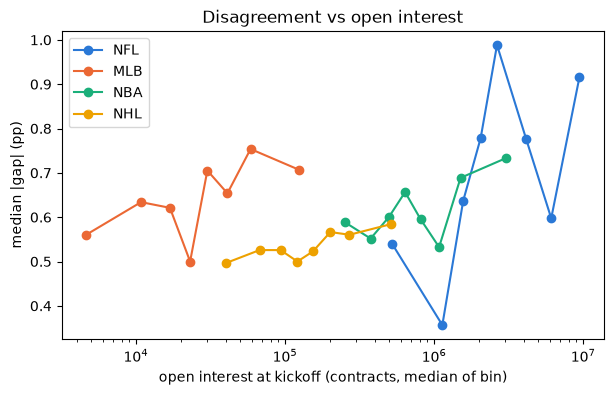

In [46]:
# Picture: median |gap| (pp) by open-interest decile, per sport
fig, ax = plt.subplots(figsize=(7, 4))
for s in SPORT_ORDER:
    d = df[df.sport == s]
    b = pd.qcut(d["log_open_interest"], 8, duplicates="drop")
    g = d.groupby(b, observed=True).agg(oi=("total_open_interest", "median"), gap=("gap_pp", lambda x: x.abs().median()))
    ax.plot(g["oi"], g["gap"], marker="o", label=s.upper(), color=SPORT_COLORS[s])
ax.set_xscale("log"); ax.set_xlabel("open interest at kickoff (contracts, median of bin)")
ax.set_ylabel("median |gap| (pp)"); ax.set_title("Disagreement vs open interest"); ax.legend();

**Reading section 5.**
- **The original hypothesis (more liquidity → smaller disagreement) is not supported for volume or open interest.** Pre-kickoff volume has no detectable effect (×1.007 per log unit, p = 0.32). Open interest goes the *other* way: each 2.7× increase in OI is associated with about 5.5% **larger** |gap| (CI +2% to +9%, p = 0.001).
- The OI result survives every check: controls with and without platform age, within each sport (MLB, NBA, NHL individually significant, NFL same direction), the median and the 90th percentile in quantile regression, and dropping low-volume games.
- **The bid-ask spread behaves as expected:** each extra cent of spread is associated with about 9% larger disagreement (p = 0.023). A wider spread means a noisier Kalshi midpoint. Note that the spread is exactly 1¢ for over 75% of games, so this effect rests on a minority of wide-spread games.
- **Interpreting the OI sign:** OI is the stock of open positions, so it's highest for marquee, heavily traded games. Those are also the games where news and money arrive closest to kickoff, so a Kalshi price taken *at* kickoff can drift from an earlier sportsbook snapshot. That fits the section 3 result (Kalshi more informed than the book). It's a hypothesis, not something these data can confirm. Getting bet365's timestamp would test it.
- `lopsided` has a big effect (×3.7 per unit). Much of that is mechanical, because the de-vig methods disagree most at extreme prices (section 1), so it's a control, not a finding.
- Platform age, season progress, postseason and number of competing leagues have no detectable effect once sport and liquidity are controlled.
- **National TV has no detectable effect.** Nationally exclusive broadcasts are associated with ×1.01 disagreement (95% CI ×0.94 to ×1.09, p = 0.77), and swapping it in for volume (the slide 8 b₃ swap) leaves the open-interest effect unchanged (×1.06, p < 0.001). Marquee status as such doesn't explain the OI result. Note that every NFL game counts as national on ESPN, so this effect is identified from MLB, NBA and NHL only.

## 6. Robustness

### 6a. De-vig method

Kalshi-only calibration (section 2) doesn't depend on the de-vig method at all. The book-side results do.

In [47]:
rows = []
for m in ["proportional", "additive", "power", "cheung"]:   # shin == additive for 2-way markets
    d = with_book_method(df, m)
    _, cb = calibration_fit(d, "logit_book")
    e = encompassing(d)
    r = gamma_fit(f"abs_logit_gap ~ log_open_interest + log_volume + {CONTROLS}", d)
    rows.append({"method": m, "book_beta": cb["beta"], "book_wald_p": cb["wald_p"],
                 "brier_book": ((d.p_book - d.home_win) ** 2).mean(),
                 "book_adds_to_kalshi": e["book_adds_to_kalshi"], "bk_p": e["bk_p"],
                 "kalshi_adds_to_book": e["kalshi_adds_to_book(-b1)"], "kb_p": e["kb_p"],
                 "OI_effect_x": np.exp(r.params["log_open_interest"]), "OI_p": r.pvalues["log_open_interest"],
                 "vol_effect_x": np.exp(r.params["log_volume"]), "vol_p": r.pvalues["log_volume"]})
sensitivity = pd.DataFrame(rows).set_index("method")
sensitivity.round(4)

,book_beta,book_wald_p,brier_book,book_adds_to_kalshi,bk_p,kalshi_adds_to_book,kb_p,OI_effect_x,OI_p,vol_effect_x,vol_p
method,,,,,,,,,,,
proportional,0.9763,0.7592,0.2302,-1.2102,0.0900,-2.1004,0.0022,1.0242,0.1476,1.0025,0.7247
additive,0.9250,0.2382,0.2303,-0.7239,0.2949,-1.6749,0.0172,1.0535,0.0015,1.0064,0.3441
power,0.8969,0.0704,0.2304,-0.2495,0.6998,-1.2035,0.0775,1.0552,0.0004,1.0072,0.2842
cheung,0.9210,0.2068,0.2303,-0.5927,0.3882,-1.5451,0.0278,1.0553,0.0009,1.0068,0.3180


### 6b. Sample restrictions: drop low-volume games; regular season only

In [48]:
samples = {"all games": df,
           "volume >= 100": df[~df.low_volume],
           "regular season": df[df.phase == "regular"]}
rows = []
for name, d in samples.items():
    _, ck = calibration_fit(d, "logit_kalshi")
    e = encompassing(d)
    ctrl = CONTROLS.replace("post + ", "") if name == "regular season" else CONTROLS
    r = gamma_fit(f"abs_logit_gap ~ log_open_interest + log_volume + {ctrl}", d)
    rows.append({"sample": name, "n": len(d), "kalshi_beta": ck["beta"], "kalshi_wald_p": ck["wald_p"],
                 "book_adds_to_kalshi": e["book_adds_to_kalshi"], "bk_p": e["bk_p"],
                 "OI_effect_x": np.exp(r.params["log_open_interest"]), "OI_p": r.pvalues["log_open_interest"],
                 "vol_effect_x": np.exp(r.params["log_volume"]), "vol_p": r.pvalues["log_volume"]})
pd.DataFrame(rows).set_index("sample").round(4)

,n,kalshi_beta,kalshi_wald_p,book_adds_to_kalshi,bk_p,OI_effect_x,OI_p,vol_effect_x,vol_p
sample,,,,,,,,,
all games,4865,0.9427,0.4464,-0.5927,0.3882,1.0553,0.0009,1.0068,0.3180
volume >= 100,3663,0.9737,0.8698,-0.4765,0.5685,1.0479,0.0188,1.0185,0.1317
regular season,4657,0.9482,0.5735,-0.6543,0.3540,1.0653,0.0002,1.0079,0.2474


**Reading section 6.**
- **De-vig method:** the qualitative conclusions hold for every method. Book calibration is not rejected for any method (power is closest, p = 0.07). The book never adds to Kalshi. Kalshi adds to the book under every method (p from 0.002 to 0.08). The positive OI effect is significant for additive, power and Cheung, but not for proportional (×1.024, p = 0.15). That fits section 1: proportional's systematic tilt adds noise to the gap that isn't related to liquidity.
- **Low-volume games:** dropping the 1,202 games with fewer than 100 contracts traded moves Kalshi's slope closer to 1 (0.97, Wald p = 0.87). This is consistent with stale quotes in thin markets adding noise. The OI effect remains (×1.048, p = 0.019).
- **Regular season only:** nothing changes. With only 207 postseason games, the playoffs don't drive any result.

## 7. Strategy and economic significance

**Rules**
- **Signal:** for each game, edge on a side = de-vigged book probability − Kalshi **ask** for that side. Take the larger edge; bet if it exceeds the threshold.
- **Costs:** pay the ask, plus Kalshi's taker fee, $0.07 \cdot P(1-P)$ per contract (rounded up to the cent at the order level; per-contract here, which slightly understates fees on small orders).
- **Stake rules:**
  - flat: 1 unit per bet
  - edge-proportional: units = edge / 0.01
  - ¼-Kelly: fraction of a fixed 100-unit bankroll, $f = \tfrac14 \cdot \frac{p - c}{1 - c}$ with $c$ = ask + fee
- **Validation:** walk-forward. On each training window, pick the (threshold, stake) combination with the best ROI (at least 30 bets), then evaluate it on the next block. Folds are balanced by game count.
- **Uncertainty:** bootstrap ROI by resampling **dates**.

The first fold trains only on MLB, since Kalshi had only MLB before September 2025.

In [49]:
FEE_RATE = 0.07  # Kalshi taker fee multiplier (fee = 0.07 * P * (1 - P) per contract)

def kalshi_fee(price):
    return FEE_RATE * price * (1 - price)


def walk_forward_splits(data, n_folds=5, min_train_frac=0.4):
    # Expanding-window folds; boundaries placed by cumulative game count and snapped to whole dates.
    games_per_date = data.groupby("game_date_et").size().sort_index()
    cum = games_per_date.cumsum() / len(data)
    targets = np.linspace(min_train_frac, 1, n_folds + 1)
    cut_dates = [cum.index[np.searchsorted(cum.values, t, side="left")] for t in targets[:-1]] + [None]
    for a, b in zip(cut_dates[:-1], cut_dates[1:]):
        train = data.index[data["game_date_et"] < a]
        test = data.index[(data["game_date_et"] >= a) & ((data["game_date_et"] < b) if b else True)]
        yield train, test


def candidate_bets(d):
    # One row per game: the better side by book-vs-ask edge, with cost per contract and payoff.
    home_edge = d["p_book"] - d["kalshi_home_ask"]
    away_edge = (1 - d["p_book"]) - d["kalshi_away_ask"]
    home = home_edge >= away_edge
    out = pd.DataFrame(index=d.index)
    out["game_date_et"] = d["game_date_et"]
    out["side"] = np.where(home, "home", "away")
    out["p"] = np.where(home, d["p_book"], 1 - d["p_book"])
    out["ask"] = np.where(home, d["kalshi_home_ask"], d["kalshi_away_ask"])
    out["edge"] = np.where(home, home_edge, away_edge)
    out["cost"] = out["ask"] + kalshi_fee(out["ask"])             # per contract, pays $1 if it wins
    out["won"] = np.where(home, d["home_win"], 1 - d["home_win"])
    out = out[(out["ask"] > 0) & (out["ask"] < 1)]
    return out


def stake_units(b, rule):
    if rule == "flat":
        return pd.Series(1.0, index=b.index)
    if rule == "edge_prop":
        return b["edge"] / 0.01
    if rule == "kelly_q":
        f = 0.25 * (b["p"] - b["cost"]) / (1 - b["cost"])
        return 100 * f.clip(lower=0)
    raise ValueError(rule)


def backtest(bets, threshold, rule):
    b = bets[bets["edge"] > threshold].copy()
    b["stake"] = stake_units(b, rule)            # dollars staked
    b = b[b["stake"] > 0]
    b["contracts"] = b["stake"] / b["cost"]
    b["pnl"] = b["contracts"] * b["won"] - b["stake"]
    return b


def summarize(b):
    staked = b["stake"].sum()
    return {"bets": len(b), "staked": staked, "pnl": b["pnl"].sum(),
            "roi": b["pnl"].sum() / staked if staked > 0 else np.nan,
            "hit_rate": b["won"].mean() if len(b) else np.nan}


def bootstrap_roi(b, n_boot=2000, seed=0):
    # 95% CI for ROI, resampling whole dates.
    if len(b) == 0:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    g = b.groupby("game_date_et").agg(pnl=("pnl", "sum"), stake=("stake", "sum"))
    idx = rng.integers(0, len(g), size=(n_boot, len(g)))
    roi = g["pnl"].values[idx].sum(1) / g["stake"].values[idx].sum(1)
    return tuple(np.percentile(roi, [2.5, 97.5]))


THRESHOLDS = [0.0, 0.01, 0.02, 0.03, 0.05]
RULES = ["flat", "edge_prop", "kelly_q"]
bets_all = candidate_bets(df)
print(f"games with a valid ask: {len(bets_all)};  share with positive edge after ask (before fees): {(bets_all.edge > 0).mean():.3f}")
print(f"mean edge vs ask: {bets_all.edge.mean()*100:.2f} pp;  mean fee per contract: {kalshi_fee(bets_all.ask).mean()*100:.2f} c")

games with a valid ask: 4865;  share with positive edge after ask (before fees): 0.466
mean edge vs ask: 0.05 pp;  mean fee per contract: 1.59 c


### 7a. Baseline: what does buying at the ask cost?

In [50]:
# Cost of trading: ROI from buying every game's home side, favorite, or underdog at the ask.
fav_home = df["p_kalshi"] >= 0.5
sides = {
    "home":     (df["kalshi_home_ask"], df["home_win"]),
    "favorite": (np.where(fav_home, df["kalshi_home_ask"], df["kalshi_away_ask"]), np.where(fav_home, df["home_win"], 1 - df["home_win"])),
    "underdog": (np.where(fav_home, df["kalshi_away_ask"], df["kalshi_home_ask"]), np.where(fav_home, 1 - df["home_win"], df["home_win"])),
}
base = {}
for name, (ask, won) in sides.items():
    ask, won = pd.Series(ask, index=df.index), pd.Series(won, index=df.index)
    ok = (ask > 0) & (ask < 1)
    ask, won = ask[ok], won[ok]
    cost = ask + kalshi_fee(ask)
    base[name] = {"bets": len(ask), "mean_price": ask.mean(), "win_rate": won.mean(),
                  "roi_at_ask": won.sum() / ask.sum() - 1, "roi_after_fees": won.sum() / cost.sum() - 1}
pd.DataFrame(base).T.round(4)

,bets,mean_price,win_rate,roi_at_ask,roi_after_fees
home,4865.0,0.5453,0.5342,-0.0202,-0.0479
favorite,4865.0,0.6221,0.5949,-0.0438,-0.0675
underdog,4865.0,0.3911,0.4051,0.0358,-0.0049


### 7b. In-sample grid (for intuition only; it's optimistic by construction)

In [51]:
grid = []
for t in THRESHOLDS:
    for r in RULES:
        grid.append({"threshold": t, "rule": r, **summarize(backtest(bets_all, t, r))})
grid = pd.DataFrame(grid)
grid.pivot(index="threshold", columns="rule", values="roi").round(4)

rule,edge_prop,flat,kelly_q
threshold,,,
0.00,-0.0606,-0.0738,-0.0375
0.01,-0.0540,-0.0493,-0.0452
0.02,-0.1210,-0.1154,-0.0852
0.03,-0.1982,-0.1543,-0.2561
0.05,-1.0000,-1.0000,-1.0000


In [52]:
grid.pivot(index="threshold", columns="rule", values="bets")

rule,edge_prop,flat,kelly_q
threshold,,,
0.00,2269,2269,124
0.01,386,386,100
0.02,46,46,46
0.03,8,8,8
0.05,1,1,1


### 7c. Walk-forward (out-of-sample)

In [53]:
fold_rows, oos = [], []
for i, (tr, te) in enumerate(walk_forward_splits(df)):
    train_bets, test_bets = bets_all.loc[bets_all.index.intersection(tr)], bets_all.loc[bets_all.index.intersection(te)]
    best, best_roi = None, -np.inf
    for t in THRESHOLDS:
        for r in RULES:
            s = summarize(backtest(train_bets, t, r))
            if s["bets"] >= 30 and s["roi"] > best_roi:
                best, best_roi = (t, r), s["roi"]
    if best is None:
        fold_rows.append({"fold": i, "chosen": "none (<30 bets)"}); continue
    b = backtest(test_bets, *best)
    oos.append(b.assign(fold=i))
    fold_rows.append({"fold": i, "test_from": df.loc[te, "game_date_et"].min(), "test_to": df.loc[te, "game_date_et"].max(),
                      "chosen": f"t={best[0]}, {best[1]}", "train_roi": best_roi, **{f"test_{k}": v for k, v in summarize(b).items()}})
wf = pd.DataFrame(fold_rows).set_index("fold")
wf.round(4)

,test_from,test_to,chosen,train_roi,test_bets,test_staked,test_pnl,test_roi,test_hit_rate
fold,,,,,,,,,
0,2025-09-25,2025-11-09,"t=0.01, flat",0.0351,38,38.0000,3.8347,0.1009,0.6579
1,2025-11-10,2025-12-17,"t=0.01, flat",0.0450,31,31.0000,-1.1185,-0.0361,0.5806
2,2025-12-18,2026-01-23,"t=0.01, flat",0.0361,43,43.0000,-5.4904,-0.1277,0.5349
3,2026-01-24,2026-03-16,"t=0.01, flat",0.0145,27,27.0000,-13.4747,-0.4991,0.3704
4,2026-03-17,2026-06-14,"t=0.0, kelly_q",0.0004,23,13.2958,-3.0137,-0.2267,0.4783


In [54]:
oos_bets = pd.concat(oos) if oos else pd.DataFrame(columns=["stake", "pnl", "won", "game_date_et"])
s = summarize(oos_bets)
lo, hi = bootstrap_roi(oos_bets)
print(f"Out-of-sample: {s['bets']} bets, staked {s['staked']:.1f} units, P&L {s['pnl']:+.1f}, "
      f"ROI {s['roi']:+.2%}  (95% date-bootstrap CI {lo:+.2%} to {hi:+.2%})")

Out-of-sample: 162 bets, staked 152.3 units, P&L -19.3, ROI -12.65%  (95% date-bootstrap CI -27.71% to +1.60%)


**Reading section 7.**
- **Trading costs swamp any edge.** The average book-vs-ask edge is 0.05 pp, while the Kalshi taker fee averages 1.6¢ per contract on top of a bid-ask spread that is usually 1¢. Buying every home side, favorite or underdog at the ask loses 0.5–6.8% after fees. Even the underdog side, which is slightly underpriced (section 2), goes from +3.6% to −0.5% once fees are paid.
- **In-sample**, no threshold/stake combination has positive ROI on the full sample. Larger thresholds leave very few bets (46 at 2 pp, 8 at 3 pp), and those lose.
- **Out-of-sample (walk-forward):** a 1 pp threshold looked mildly profitable on early training windows, but out of sample the chosen rules lost money in 4 of 5 folds. Overall: 162 bets, ROI −12.7% (95% date-bootstrap CI −27.7% to +1.6%).
- **Conclusion:** no exploitable strategy from following the sportsbook against Kalshi exists in this sample after realistic costs. Statistically and economically, the markets are efficient relative to each other at this resolution.
- **Caveats:** this uses closing quotes, not order-book depth, so large stakes would face worse prices. Fees are applied per contract without rounding. Both caveats make the real result *worse*, not better.

## 8. Price leadership: when the venues disagree, who has the information? *(exploratory)*

Kalshi and bet365 agree closely (EDA; sections 1–3). This section asks about the small disagreements that remain, and it ties together two results from the first round:
- Section 3: Kalshi's closing price **encompasses** bet365's line, but not the reverse.
- Section 5: disagreement **grows** with open interest, the opposite of the original liquidity hypothesis.

**Hypothesis (H-L).** Late price discovery happens on Kalshi, and bet365's listed closing line only partly follows it. Liquid (high-OI) games have more late discovery, which produces the OI effect.

**What we can and can't see.** Kalshi is observed at four times (T−24h, T−6h, T−2h, close), but bet365 only once (its listed closing line, time unknown). So "leadership" here means *Kalshi's close contains information bet365's line doesn't, and bet365 sits partway along Kalshi's late price path*. We cannot trace bet365's own price path.

**Specification, fixed on 2026-11-10 before running.** (One descriptive check was seen while brainstorming: bet365 is closest to Kalshi's *close*, and the gap correlates −0.29 with Kalshi's T−2h move.) Main horizon: **T−2h**, available for 4,864 of 4,865 games. T−6h is the robustness horizon. All standard errors are clustered by date.

| | Test | Prediction under H-L |
|---|---|---|
| 8a | **Partial adjustment:** $\text{logit}\,p_B - \text{logit}\,p_{K,T-2h} = c + \lambda\,(\text{logit}\,p_{K,\text{close}} - \text{logit}\,p_{K,T-2h})$ | $0 < \lambda < 1$: bet365 has absorbed part, not all, of Kalshi's last-two-hours move |
| 8b | **Bracketing:** encompassing test of bet365 against Kalshi's *earlier* prices, $\text{win} \sim \text{logit}\,p_{K,T-h} + (\text{logit}\,p_B - \text{logit}\,p_{K,T-h})$ | The gap coefficient is positive against T−2h (bet365 knows more than Kalshi did two hours out), while section 3 shows it adds nothing against the close |
| 8c | **Who's right depends on late movement:** section 3's Kalshi-adds-to-book test, split by whether Kalshi's late move $\lvert\text{move}_{2h}\rvert$ is above or below its median, with an interaction test | Kalshi's extra information is concentrated in big-late-move games |
| 8d | **Mediation of the OI effect:** (i) does OI predict $\lvert\text{move}_{2h}\rvert$? (ii) the section 5 Gamma model with and without $\lvert\text{move}_{2h}\rvert$, on the same games | OI → bigger late moves, and adding the late move **attenuates** the OI coefficient |

**Decision rule for 8d,** set in advance. Attenuation = $1 - \hat\gamma_{OI,\text{with move}} / \hat\gamma_{OI,\text{without}}$, with a 95% CI from resampling dates (200 draws). At least 50%: late price discovery *largely explains* the OI effect. 20–50%: it explains it *partly*. Under 20%, or a CI that includes 0: it *doesn't* explain it.

**Noise check (built in).** Kalshi's close appears in both the late move ($\text{close} - T{-}2h$) and the gap ($\text{book} - \text{close}$), so noise in the closing midpoint mechanically links them with a negative sign. Each test is repeated with the T−6h → T−2h move, which doesn't involve the close. If the results survive there, noise isn't driving them.

In [55]:
# 8a. Where does bet365 sit along Kalshi's price path?
PL_H = 2   # main horizon, fixed in advance; T-6h is the robustness horizon
PL_READY = all(f"logit_kalshi_{h}h" in df for h in (24, 6, 2))
if not PL_READY:
    print("Section 8 needs early Kalshi prices: run scripts/fetch_kalshi_early_prices.py, "
          "then analysis/build_model_table.py.")


def partial_adjustment(d, early, late):
    # (logit_book - early) = c + lam * (late - early). lam = 1: book fully reflects Kalshi's move from early to late.
    d = d.assign(y=d["logit_book"] - d[early], x=d[late] - d[early]).dropna(subset=["y", "x"])
    r = smf.ols("y ~ x", data=d).fit(**cluster(d))
    lo, hi = r.conf_int().loc["x"]
    p1 = float(np.asarray(r.t_test("x = 1").pvalue).squeeze())
    return {"n": int(r.nobs), "lambda": r.params["x"], "lo": lo, "hi": hi,
            "p(lambda=0)": r.pvalues["x"], "p(lambda=1)": p1}


if PL_READY:
    # Distance from the bet365 line to Kalshi's price at each time, on a common sample per row
    dist = {}
    for name, cols in [("games with T-24h, T-6h, T-2h quotes", [24, 6, 2]), ("games with T-6h, T-2h quotes", [6, 2])]:
        s = df.dropna(subset=[f"logit_kalshi_{h}h" for h in cols])
        row = {f"Kalshi T-{h}h": (s["logit_book"] - s[f"logit_kalshi_{h}h"]).abs().mean() for h in cols}
        row["Kalshi close"] = (s["logit_book"] - s["logit_kalshi"]).abs().mean()
        dist[name] = {"n": len(s), **row}
    print("Mean |logit(bet365) - logit(Kalshi at time t)|  (smaller = closer)")
    display(pd.DataFrame(dist).T.round(4))

    pa = {
        "T-2h -> close (main)": partial_adjustment(df, "logit_kalshi_2h", "logit_kalshi"),
        "T-6h -> close": partial_adjustment(df, "logit_kalshi_6h", "logit_kalshi"),
        "T-6h -> T-2h (noise check: no close price)": partial_adjustment(df, "logit_kalshi_6h", "logit_kalshi_2h"),
    }
    print("Partial adjustment: share of Kalshi's move that bet365's line reflects")
    display(pd.DataFrame(pa).T.round(4))
    display(by_sport(df, lambda d: partial_adjustment(d, "logit_kalshi_2h", "logit_kalshi")).round(4))

Mean |logit(bet365) - logit(Kalshi at time t)|  (smaller = closer)


,n,Kalshi T-24h,Kalshi T-6h,Kalshi T-2h,Kalshi close
"games with T-24h, T-6h, T-2h quotes",2890.0,0.123,0.0683,0.0528,0.0344
"games with T-6h, T-2h quotes",4585.0,NaN,0.0611,0.0452,0.0337


Partial adjustment: share of Kalshi's move that bet365's line reflects


,n,lambda,lo,hi,p(lambda=0),p(lambda=1)
T-2h -> close (main),4864.0,0.7994,0.7582,0.8405,0.0,0.0000
T-6h -> close,4585.0,0.8783,0.8542,0.9023,0.0,0.0000
T-6h -> T-2h (noise check: no close price),4585.0,1.0021,0.9557,1.0485,0.0,0.9295


,n,lambda,lo,hi,p(lambda=0),p(lambda=1)
sample,,,,,,
pooled,4864,0.7994,0.7582,0.8405,0.0,0.0000
nfl,276,0.6295,0.4258,0.8333,0.0,0.0004
mlb,1990,0.5449,0.4715,0.6183,0.0,0.0000
nba,1214,0.8785,0.8394,0.9177,0.0,0.0000
nhl,1384,0.8516,0.8087,0.8945,0.0,0.0000


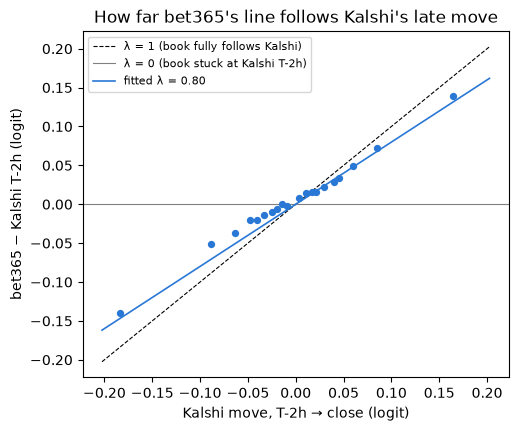

In [56]:
# Picture: bet365 vs Kalshi's late move, binned
if PL_READY:
    s = df.dropna(subset=["logit_kalshi_2h"]).assign(
        x=lambda d: d["logit_kalshi"] - d["logit_kalshi_2h"], y=lambda d: d["logit_book"] - d["logit_kalshi_2h"])
    s = s[s["x"].abs() > 1e-9]   # games where Kalshi moved
    b = pd.qcut(s["x"], 20, duplicates="drop")
    g = s.groupby(b, observed=True)[["x", "y"]].mean()
    lam = pa["T-2h -> close (main)"]["lambda"]
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    lim = np.abs(g.values).max() * 1.1
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=0.8, label="λ = 1 (book fully follows Kalshi)")
    ax.axhline(0, color="grey", lw=0.8, label="λ = 0 (book stuck at Kalshi T-2h)")
    ax.plot([-lim, lim], [-lim * lam, lim * lam], color="#2a78d6", lw=1.2, label=f"fitted λ = {lam:.2f}")
    ax.scatter(g["x"], g["y"], s=18, color="#2a78d6", zorder=3)
    ax.set_xlabel("Kalshi move, T-2h → close (logit)"); ax.set_ylabel("bet365 − Kalshi T-2h (logit)")
    ax.set_title("How far bet365's line follows Kalshi's late move"); ax.legend(fontsize=8);

In [57]:
# 8b. Bracketing: does bet365 add information to Kalshi's EARLIER prices?
def encompass_vs(d, kalshi_col):
    # home_win ~ kalshi_col + (logit_book - kalshi_col). Positive gap coefficient = bet365 adds to that Kalshi price.
    d = d.dropna(subset=[kalshi_col]).assign(g=lambda x: x["logit_book"] - x[kalshi_col])
    r = smf.logit(f"home_win ~ {kalshi_col} + g", data=d).fit(disp=0, **cluster(d))
    lo, hi = r.conf_int().loc["g"]
    return {"n": int(r.nobs), "book_adds_coef": r.params["g"], "lo": lo, "hi": hi, "p": r.pvalues["g"]}


if PL_READY:
    bracket = {f"vs Kalshi T-{h}h": encompass_vs(df, f"logit_kalshi_{h}h") for h in (24, 6, 2)}
    bracket["vs Kalshi close (= section 3)"] = encompass_vs(df, "logit_kalshi")
    display(pd.DataFrame(bracket).T.round(4))
    display(by_sport(df, lambda d: encompass_vs(d, "logit_kalshi_2h")).round(4))

,n,book_adds_coef,lo,hi,p
vs Kalshi T-24h,2890.0,1.1939,0.7144,1.6733,0.0000
vs Kalshi T-6h,4585.0,0.9455,0.2608,1.6303,0.0068
vs Kalshi T-2h,4864.0,0.8072,-0.0218,1.6363,0.0563
vs Kalshi close (= section 3),4865.0,-0.5927,-1.9389,0.7535,0.3882


,n,book_adds_coef,lo,hi,p
sample,,,,,
pooled,4864,0.8072,-0.0218,1.6363,0.0563
nfl,276,1.7748,-1.6023,5.1519,0.3030
mlb,1990,0.7666,-1.0237,2.5570,0.4013
nba,1214,1.1124,0.0432,2.1817,0.0414
nhl,1384,-0.4829,-2.9104,1.9445,0.6966


In [58]:
# 8c. Is Kalshi's extra information concentrated in games where Kalshi moved late?
if PL_READY:
    def late_split(move_col):
        d = df.dropna(subset=[move_col]).copy()
        d["late_big"] = (d[move_col].abs() > d[move_col].abs().median()).astype(int)
        rows = {"small late move": encompassing(d[d.late_big == 0]), "big late move": encompassing(d[d.late_big == 1])}
        # Interaction on the book-based form: negative = more Kalshi information in big-move games
        r = smf.logit("home_win ~ logit_book + late_big + logit_gap + logit_gap:late_big", data=d).fit(disp=0, **cluster(d))
        lo, hi = r.conf_int().loc["logit_gap:late_big"]
        rows["interaction (big - small)"] = {"n": int(r.nobs), "kalshi_adds_to_book(-b1)": r.params["logit_gap:late_big"],
                                             "kb_lo": lo, "kb_hi": hi, "kb_p": r.pvalues["logit_gap:late_big"]}
        return pd.DataFrame(rows).T[["n", "kalshi_adds_to_book(-b1)", "kb_lo", "kb_hi", "kb_p",
                                      "book_adds_to_kalshi", "bk_p"]]

    df["move_6h_2h"] = df["logit_kalshi_2h"] - df["logit_kalshi_6h"]   # noise check: no close price
    print("Split by |move T-2h -> close| (main)")
    display(late_split(f"move_{PL_H}h").round(4))
    print("Split by |move T-6h -> T-2h| (noise check)")
    display(late_split("move_6h_2h").round(4))

Split by |move T-2h -> close| (main)


,n,kalshi_adds_to_book(-b1),kb_lo,kb_hi,kb_p,book_adds_to_kalshi,bk_p
small late move,2437.0,-0.9873,-3.2919,1.3172,0.4011,-0.0041,0.9972
big late move,2427.0,-1.8959,-3.6624,-0.1293,0.0354,-0.9731,0.2729
interaction (big - small),4864.0,-1.1702,-3.9925,1.6521,0.4164,NaN,NaN


Split by |move T-6h -> T-2h| (noise check)


,n,kalshi_adds_to_book(-b1),kb_lo,kb_hi,kb_p,book_adds_to_kalshi,bk_p
small late move,2295.0,-2.2578,-4.2263,-0.2892,0.0246,-1.3198,0.1796
big late move,2290.0,-1.1197,-3.1201,0.8807,0.2726,-0.1313,0.8961
interaction (big - small),4585.0,1.3614,-1.3555,4.0784,0.3260,NaN,NaN


In [59]:
# 8d. Does late price discovery explain the open-interest effect? (mediation)
GAMMA = sm.families.Gamma(sm.families.links.Log())


def mediation(move_col, n_boot=200, seed=0):
    d = df.dropna(subset=[move_col]).assign(abs_move=lambda x: x[move_col].abs())
    f0 = f"abs_logit_gap ~ log_open_interest + log_volume + {CONTROLS}"
    f1 = f"abs_logit_gap ~ log_open_interest + log_volume + abs_move + {CONTROLS}"
    first = smf.ols(f"abs_move ~ log_open_interest + log_volume + {CONTROLS}", data=d).fit(**cluster(d))
    r0, r1 = gamma_fit(f0, d), gamma_fit(f1, d)

    # Attenuation CI: resample whole dates, refit both models
    rng = np.random.default_rng(seed)
    by_date = {k: g for k, g in d.groupby("game_date_et")}
    dates = np.array(list(by_date))
    att = []
    for _ in range(n_boot):
        bs = pd.concat([by_date[k] for k in rng.choice(dates, len(dates))], ignore_index=True)
        try:
            b0 = smf.glm(f0, data=bs, family=GAMMA).fit().params["log_open_interest"]
            b1 = smf.glm(f1, data=bs, family=GAMMA).fit().params["log_open_interest"]
            att.append(1 - b1 / b0)
        except Exception:
            pass
    a = 1 - r1.params["log_open_interest"] / r0.params["log_open_interest"]
    ci0, ci1 = r0.conf_int().loc["log_open_interest"], r1.conf_int().loc["log_open_interest"]
    return {"n": int(r1.nobs),
            "OI -> |move| (coef)": first.params["log_open_interest"], "OI->move p": first.pvalues["log_open_interest"],
            "OI x, without move": np.exp(r0.params["log_open_interest"]), "lo0": np.exp(ci0[0]), "hi0": np.exp(ci0[1]),
            "p0": r0.pvalues["log_open_interest"],
            "OI x, with move": np.exp(r1.params["log_open_interest"]), "lo1": np.exp(ci1[0]), "hi1": np.exp(ci1[1]),
            "p1": r1.pvalues["log_open_interest"],
            "|move| x per 0.1 logit": np.exp(0.1 * r1.params["abs_move"]), "move p": r1.pvalues["abs_move"],
            "attenuation": a, "att_lo": np.quantile(att, 0.025), "att_hi": np.quantile(att, 0.975),
            "boot draws": len(att)}


if PL_READY:
    med = pd.DataFrame({
        "T-2h -> close (main)": mediation(f"move_{PL_H}h"),
        "T-6h -> close": mediation("move_6h"),
        "T-6h -> T-2h (noise check)": mediation("move_6h_2h"),
    }).T
    display(med.round(4))

,n,OI -> |move| (coef),OI->move p,"OI x, without move",lo0,hi0,p0,"OI x, with move",lo1,hi1,p1,|move| x per 0.1 logit,move p,attenuation,att_lo,att_hi,boot draws
T-2h -> close (main),4864.0,0.0034,0.0013,1.0549,1.0217,1.0891,0.0010,1.0461,1.0151,1.0781,0.0033,1.2761,0.0000,0.1555,0.0498,0.4092,200.0
T-6h -> close,4585.0,0.0052,0.0002,1.0667,1.0322,1.1024,0.0001,1.0569,1.0240,1.0909,0.0006,1.1846,0.0000,0.1431,0.0701,0.3021,200.0
T-6h -> T-2h (noise check),4585.0,0.0022,0.0274,1.0667,1.0322,1.1024,0.0001,1.0662,1.0316,1.1020,0.0001,1.0350,0.1347,0.0080,-0.0034,0.0381,200.0


**Reading section 8.**

**Verdict: H-L is half supported.** Kalshi does lead bet365 in the final hours before the game, and its closing price holds information bet365's line doesn't. But that leadership does **not** explain the open-interest effect.

- **8a: bet365's line sits just behind Kalshi's close.** It is closest to Kalshi's closing price (mean |logit gap| 0.034, versus 0.045 at T−2h and 0.123 at T−24h). It reflects **λ = 0.80** of Kalshi's final-two-hours move (95% CI 0.76–0.84), rejecting both λ = 0 and λ = 1.
  - **Noise check:** bet365 fully reflects Kalshi's T−6h → T−2h moves (λ = 1.00, CI 0.96–1.05). So bet365 isn't generally sluggish; the shortfall is confined to the final two hours.
  - **Not closing-price noise:** in games with a 1¢ spread (75% of games), where the closing midpoint can be off by at most half a cent, λ is still 0.82. *(Post-hoc check, not pre-specified.)*
  - **By sport:** the lag is smallest in the NBA (0.88) and NHL (0.85) and largest in the NFL (0.63) and MLB (0.54).
- **8b: bracketing confirms it.** bet365 adds information to Kalshi's T−24h price (p < 0.001) and T−6h price (p = 0.007), marginally to its T−2h price (p = 0.056), and nothing to its close (p = 0.39, section 3). bet365's information therefore sits between Kalshi's price about two hours out and its close. This test uses outcomes, not the closing midpoint, so it's free of the noise concern. NBA is individually significant at T−2h (p = 0.04).
- **8c: not supported.** In the main split, Kalshi's extra information is significant only in big-late-move games (p = 0.035, versus p = 0.40 for small moves), but the difference between the two isn't significant (interaction p = 0.42), and the noise-check split goes the other way. There's no reliable evidence that Kalshi's advantage is concentrated in late-news games.
- **8d: late price discovery doesn't explain the OI effect.** High-OI games do have bigger late Kalshi moves (p ≤ 0.03 in all three versions), and bigger late moves come with bigger gaps. But adding the late move shrinks the OI effect by only **16%** (CI 5–41%): 14% at T−6h and 1% in the noise check, where the late move doesn't even predict the gap (p = 0.13). By the rule fixed in advance (under 20%), the OI effect stays **unexplained**: open question for future work, e.g. with bet365 timestamps.
- **Write-up phrasing:** "When the two venues disagree, the disagreement reflects price discovery on Kalshi in the last hours before the game that bet365's listed line hasn't fully absorbed. Kalshi's close contains bet365's information, but not vice versa. This leadership does not account for why disagreement rises with open interest." 

## 9. Where are the markets least efficient? *(exploratory)*

Overall, Kalshi passes every efficiency test. This section asks whether that hides **pockets** of inefficiency: types of game where prices are systematically off.

**The danger.** Slice 4,865 games enough ways and some slice will look inefficient by chance. With 24 tests at the 5% level, you expect about one false positive even if every market is perfectly efficient. So:
1. The subgroups below are **fixed in advance** (2026-11-10, before running), each with a stated reason.
2. Every p-value is corrected across the whole family with **Holm's method**. A subgroup counts as "inefficient" only if it survives that correction.
3. Rankings by point estimate aren't used, because small subgroups have noisy estimates and will top any ranking by chance.

**Subgroups** (each compared with the rest of its universe):

| Subgroup | Why it might be less efficient | Share of games |
|---|---|---|
| Thin market: total volume < 100 contracts | Few traders, so stale quotes. Dropping these moved Kalshi's β from 0.94 to 0.97 (section 6b) | ~25% |
| Wide spread: average bid-ask > 1¢ | Less competition between market makers, and a noisier midpoint | ~25% |
| Early regular season: first 15% of each sport's season | Less information about this season's teams | ~15% of regular season |
| Postseason | More attention and more recreational money, which could push either way | ~4% |
| Extreme price: Kalshi p < 0.30 or > 0.70 | Where the favorite-longshot bias lives | ~17% |
| Late news: \|Kalshi move T−2h → close\| in the top quartile | Big late information. Does the close fully absorb it? (links to section 4) | 25% |
| Busy day: total games that day in the top quartile | Limited attention: traders spread across many games | ~25% |
| National TV (MLB, NBA, NHL only) | Marquee games draw more recreational bettors, and also more attention | ~13% |

**Three tests per subgroup** (24 in total, all Holm-corrected together):
- **Calibration** within the subgroup: joint Wald test of α = 0, β = 1 (section 2). A rejection means Kalshi's prices are systematically wrong there.
- **Different from the rest:** does the calibration line (intercept and slope) differ from the complement? This is an interaction test.
- **Semi-strong** within the subgroup: does bet365 add information to Kalshi there (section 3)?

**Economic follow-up, set in advance.** For any subgroup whose calibration test survives Holm, compute the ROI of trading against the mispricing: buy the underdog at the ask if β < 1 (prices too extreme), or the favorite if β > 1. Report it before and after fees, with a date-bootstrap CI. If no subgroup survives, there's no follow-up, and the answer is "no detectable pocket of mispricing at this sample size".

In [60]:
# 9. Pre-specified subgroups -> calibration, difference-from-rest and semi-strong tests, Holm-corrected
from statsmodels.stats.multitest import multipletests

ALL = pd.Series(True, index=df.index)
top_q = lambda s: s >= s.quantile(0.75)
SUBGROUPS = [  # (name, universe, subgroup within universe) -- fixed in advance, see table above
    ("thin market (volume < 100)", ALL, df["low_volume"].astype(bool)),
    ("wide spread (> 1c)", ALL, df["ba_spread_c"] > 1.0001),
    ("early regular season (first 15%)", ~df["postseason"].astype(bool), df["season_progress"] < 0.15),
    ("postseason", ALL, df["postseason"].astype(bool)),
    ("extreme price (p < .30 or > .70)", ALL, (df["p_kalshi"] < 0.30) | (df["p_kalshi"] > 0.70)),
    ("busy day (games today, top 25%)", ALL, top_q(df["n_games_today"])),
]
if "move_2h" in df:
    SUBGROUPS.insert(5, ("late news (|move T-2h->close|, top 25%)", df["move_2h"].notna(), top_q(df["move_2h"].abs())))
if "national_tv" in df:
    SUBGROUPS.append(("national TV (MLB/NBA/NHL)", (df["sport"] != "nfl") & df["national_tv"].notna(), df["national_tv"] == 1))


def subgroup_tests(uni, grp):
    u = df[uni].copy()
    u["g"] = grp[uni].astype(int)
    G, R = u[u["g"] == 1], u[u["g"] == 0]
    _, cg = calibration_fit(G, "logit_kalshi")
    _, cr = calibration_fit(R, "logit_kalshi")
    inter = smf.logit("home_win ~ logit_kalshi * g", data=u).fit(disp=0, **cluster(u))
    diff = inter.wald_test("g = 0, logit_kalshi:g = 0", scalar=True)
    e = encompassing(G)
    return {"n_group": len(G), "n_rest": len(R),
            "beta_group": cg["beta"], "beta_lo": cg["beta_lo"], "beta_hi": cg["beta_hi"],
            "alpha_group": cg["alpha"], "beta_rest": cr["beta"],
            "p_calibration": cg["wald_p"], "p_differs": float(diff.pvalue), "p_book_adds": e["bk_p"]}


sub = pd.DataFrame({name: subgroup_tests(uni, grp) for name, uni, grp in SUBGROUPS}).T
PCOLS = ["p_calibration", "p_differs", "p_book_adds"]
flat = sub[PCOLS].to_numpy().ravel()
reject, p_holm, _, _ = multipletests(flat, alpha=0.05, method="holm")
for j, c in enumerate(PCOLS):
    sub[c + "_holm"] = p_holm.reshape(len(sub), len(PCOLS))[:, j]
print(f"{len(flat)} tests; {int(reject.sum())} survive Holm correction at 5%; "
      f"{int((flat < 0.05).sum())} would be 'significant' uncorrected.")
sub[["n_group", "beta_group", "beta_lo", "beta_hi", "beta_rest", "alpha_group",
     "p_calibration", "p_calibration_holm", "p_differs", "p_differs_holm", "p_book_adds", "p_book_adds_holm"]].round(4)

24 tests; 0 survive Holm correction at 5%; 2 would be 'significant' uncorrected.


,n_group,beta_group,beta_lo,beta_hi,beta_rest,alpha_group,p_calibration,p_calibration_holm,p_differs,p_differs_holm,p_book_adds,p_book_adds_holm
thin market (volume < 100),1202.0,0.7395,0.4473,1.0317,0.9737,-0.0094,0.1533,1.0,0.2857,1.0000,0.3206,1.0
wide spread (> 1c),1210.0,0.7785,0.5092,1.0478,0.9758,-0.0021,0.2357,1.0,0.3855,1.0000,0.1881,1.0
early regular season (first 15%),705.0,1.2040,0.9064,1.5016,0.9109,0.0235,0.3957,1.0,0.1834,1.0000,0.5670,1.0
postseason,208.0,0.8588,0.3380,1.3796,0.9482,-0.1549,0.2768,1.0,0.3863,1.0000,0.6202,1.0
extreme price (p < .30 or > .70),832.0,1.0720,0.9359,1.2080,0.7324,-0.0334,0.5838,1.0,0.0045,0.1085,0.0493,1.0
"late news (|move T-2h->close|, top 25%)",1216.0,0.9690,0.8016,1.1364,0.9273,0.0072,0.9346,1.0,0.8548,1.0000,0.1343,1.0
"busy day (games today, top 25%)",1235.0,1.0340,0.8593,1.2087,0.9005,0.0031,0.9248,1.0,0.4225,1.0000,0.3092,1.0
national TV (MLB/NBA/NHL),554.0,1.0036,0.5977,1.4095,0.9342,-0.0505,0.8497,1.0,0.8874,1.0000,0.8275,1.0


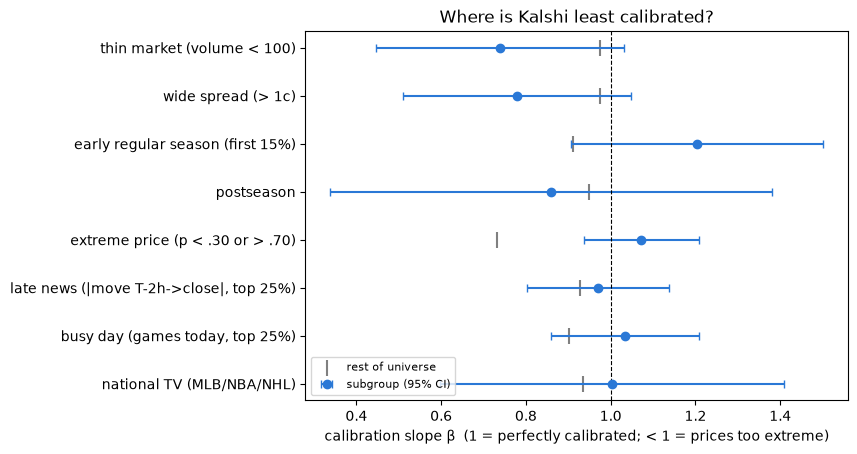

In [61]:
# Picture: Kalshi calibration slope by subgroup (95% CI) vs the rest of its universe
fig, ax = plt.subplots(figsize=(7, 0.45 * len(sub) + 1.2))
y = np.arange(len(sub))[::-1]
ax.errorbar(sub["beta_group"], y, xerr=[sub["beta_group"] - sub["beta_lo"], sub["beta_hi"] - sub["beta_group"]],
            fmt="o", color="#2a78d6", capsize=3, label="subgroup (95% CI)")
ax.scatter(sub["beta_rest"], y, marker="|", s=120, color="grey", label="rest of universe")
ax.axvline(1, color="k", ls="--", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(sub.index)
ax.set_xlabel("calibration slope β  (1 = perfectly calibrated; < 1 = prices too extreme)")
ax.set_title("Where is Kalshi least calibrated?"); ax.legend(fontsize=8, loc="lower left");

In [62]:
# Economic follow-up (pre-specified): only for subgroups whose calibration test survives Holm
flagged = sub.index[sub["p_calibration_holm"] < 0.05]
if len(flagged) == 0:
    print("No subgroup's calibration test survives Holm correction: no detectable pocket of mispricing, "
          "so no follow-up strategy is run.")
else:
    rng = np.random.default_rng(0)
    rows = {}
    for name in flagged:
        uni, grp = next((u, g) for n, u, g in SUBGROUPS if n == name)
        G = df[uni & grp]
        dog = sub.loc[name, "beta_group"] < 1          # beta < 1: prices too extreme -> buy underdogs
        home = (G["p_kalshi"] < 0.5) if dog else (G["p_kalshi"] >= 0.5)
        ask = np.where(home, G["kalshi_home_ask"], G["kalshi_away_ask"])
        win = np.where(home, G["home_win"], 1 - G["home_win"])
        t = pd.DataFrame({"date": G["game_date_et"].to_numpy(), "ask": ask, "win": win})
        t["pnl_pre"] = t["win"] - t["ask"]
        t["pnl_post"] = t["pnl_pre"] - kalshi_fee(t["ask"])
        t["stake_post"] = t["ask"] + kalshi_fee(t["ask"])
        per = t.groupby("date")[["pnl_pre", "pnl_post", "ask", "stake_post"]].sum()
        boot = []
        for _ in range(2000):
            s = per.iloc[rng.integers(0, len(per), len(per))].sum()
            boot.append(s["pnl_post"] / s["stake_post"])
        rows[name] = {"side": "underdog" if dog else "favorite", "bets": len(t),
                      "ROI before fees": per["pnl_pre"].sum() / per["ask"].sum(),
                      "ROI after fees": per["pnl_post"].sum() / per["stake_post"].sum(),
                      "after-fee lo": np.quantile(boot, 0.025), "after-fee hi": np.quantile(boot, 0.975)}
    display(pd.DataFrame(rows).T.round(4))

No subgroup's calibration test survives Holm correction: no detectable pocket of mispricing, so no follow-up strategy is run.


**Reading section 9.**

**Verdict: no pocket of detectable mispricing.** None of the 24 pre-specified tests survives Holm correction. Two would look "significant" uncorrected, both for the extreme-price subgroup, which is about what chance alone produces across 24 tests. Kalshi's efficiency is broad-based, not an average hiding inefficient corners. No follow-up strategy was run.

What the point estimates suggest (direction only, none significant):
- **Thin markets** (β = 0.74, CI 0.45–1.03) and **wide-spread games** (β = 0.78, CI 0.51–1.05) lean toward prices that are too extreme, consistent with section 6b. These two subgroups overlap heavily (mostly early-season MLB), so they are one hint, not two.
- **Extreme prices are, if anything, the best calibrated** (β = 1.07, CI 0.94–1.21), while games priced 0.30–0.70 have β = 0.73. The difference has uncorrected p = 0.0045 but Holm p = 0.11. Any over-extremity sits in mid-range prices, not among longshots, the opposite of where favorite-longshot bias usually appears. This is an exploratory hint, and slopes estimated on a narrow price range are noisy.
- Early season (β = 1.20), late news (0.97), busy days (1.03), national TV (1.00) and postseason (0.86, n = 208) show nothing.

**Write-up phrasing:** "Across eight pre-specified types of game, including thin markets, wide spreads, early season, late news and nationally televised games, we find no subgroup in which Kalshi's prices are detectably miscalibrated or in which the sportsbook adds information, after correcting for multiple comparisons." 

## Summary: answers to the research questions

**Q3: Are these sports prediction markets significantly inefficient?** No, at the resolution these data allow.
| Form | Test | Result |
|---|---|---|
| Calibration (baseline) | logit(win) on logit(price), joint α=0, β=1 | Not rejected for Kalshi (p = 0.45) or bet365 (p = 0.21). β ∈ [0.84, 1.04] for Kalshi |
| Weak | does line movement from T−24/6/2h add to the close? | No: γ not significant at any horizon (p = 0.20, 0.53, 0.50). A 1-SD move is worth at most about +3.8 pp at T−24h |
| Semi-strong | does the public sportsbook price add to Kalshi? | No (p = 0.39). The reverse holds: Kalshi adds to bet365 (p = 0.028) |
| Strong | private information | Not testable with public data |

**Q2: How do liquidity and volume relate to inefficiency?** Pre-kickoff volume: no relationship. National TV: no relationship. Wider bid-ask spreads: larger disagreement, as expected. Open interest: *larger* disagreement, robustly. The likely reason is that heavily traded games move more near kickoff, relative to an earlier book snapshot. This is a hypothesis to state, not a result.

**Q1: Is there a profitable strategy?** No. The edge versus the ask averages 0.05 pp against about 1.6¢ in fees. Walk-forward ROI is −12.7% (CI −27.7% to +1.6%).

**Price leadership (section 8, exploratory):** The venues agree closely, and when they disagree, Kalshi leads. bet365's line reflects all of Kalshi's movement up to two hours before the game but only 80% (CI 76–84%) of its final-two-hours move, and bet365's information sits between Kalshi's T−2h price and its close. This late leadership does **not** explain the open-interest effect: adding it shrinks the OI coefficient by only 16%, under the 20% threshold fixed in advance.

**Where markets are least efficient (section 9, exploratory):** Nowhere detectably. 0 of 24 pre-specified subgroup tests survive Holm correction. Thin and wide-spread markets lean toward over-extreme prices, but not significantly.

**De-vigging (prof. comment #3):** the method flips the sign of the mean gap but doesn't change any conclusion above (section 6a).

**Season / sport / time (prof. comment #4):** sport, postseason, season progress, platform age and competing leagues are all controlled. Slopes don't differ by sport, and postseason and regular-season-only results match. The one caveat: platform age and sport are confounded, because MLB is the only sport from Kalshi's first months.

**Limitations:** single season per sport; a single sportsbook with an unknown snapshot time; closing quotes only (no depth); 9 NFL playoff games.